In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [42]:
# Professional visualization defaults
sns.set_theme(style='darkgrid', context='notebook', palette='deep')

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 150,
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.titleweight": "bold"
}) 

# Reusable visualization helper
def finish_plot(title=None, xlabel=None, ylabel=None, rotation=0):
    if title:
        plt.title(title, pad=14, weight='bold')
    if xlabel:
        plt.xlabel(xlabel)
    if ylabel:
        plt.ylabel(ylabel)

    plt.xticks(rotation=rotation, ha='right' if rotation else 'center')
    sns.despine()
    plt.tight_layout()
    plt.show()

In [43]:
df = pd.read_excel("Thesis_Project_Dataset_1000_Rows.xlsx")

print(f"Data Set dimensions {df.shape[0]} rows and {df.shape[1]} columns\n")
print("First 5 row:")
display(df.head(5))
print("Random Samples:")
display(df.sample(5))

Data Set dimensions 1004 rows and 7 columns

First 5 row:


,ID,Date,Category,Sales,Quantity,Discount,Customer_Code
0,1001,2023-04-13,Category C,2484.68,20,0.0,CUST-0001
1,1002,2023-12-15,Category C,4379.77,6,0.0,CUST-0002
2,1003,2023-09-28,Category A,4513.44,27,0.0,CUST-0003
3,1004,2023-04-17,Category B,2166.43,2,0.0,CUST-0004
4,1005,2023-03-13,Category B,1456.46,29,0.0,CUST-0005


Random Samples:


,ID,Date,Category,Sales,Quantity,Discount,Customer_Code
634,1635,2023-07-21,Category A,2240.57,38,0.00,CUST-0635
149,1150,2023-01-29,Category A,1772.11,39,0.05,CUST-0150
707,1708,2023-02-15,Category C,2611.26,1,0.00,CUST-0708
617,1618,2023-05-16,Category A,4175.32,43,0.10,CUST-0618
39,1040,2023-09-01,Category C,2646.89,34,0.05,CUST-0040


In [44]:
print("Data set columns names:", df.columns.tolist())

Data set columns names: ['ID', 'Date', 'Category', 'Sales', 'Quantity', 'Discount', 'Customer_Code']


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             1004 non-null   int64  
 1   Date           1004 non-null   str    
 2   Category       984 non-null    str    
 3   Sales          974 non-null    float64
 4   Quantity       1004 non-null   int64  
 5   Discount       979 non-null    float64
 6   Customer_Code  1004 non-null   str    
dtypes: float64(2), int64(2), str(3)
memory usage: 55.0 KB


In [46]:
print("Data type of each columns\n",df.dtypes)
print("\n")
print("Memory usages of each columns\n", df.memory_usage(deep=True))

Data type of each columns
 ID                 int64
Date                 str
Category             str
Sales            float64
Quantity           int64
Discount         float64
Customer_Code        str
dtype: object


Memory usages of each columns
 Index              132
ID                8032
Date             59236
Category         58696
Sales             8032
Quantity          8032
Discount          8032
Customer_Code    60240
dtype: int64


### Visual Data Profiling
The following charts provide a quick visual overview of the dataset structure and numerical variables.

C:\Users\Laptop\AppData\Local\Temp\ipykernel_6440\4250828024.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


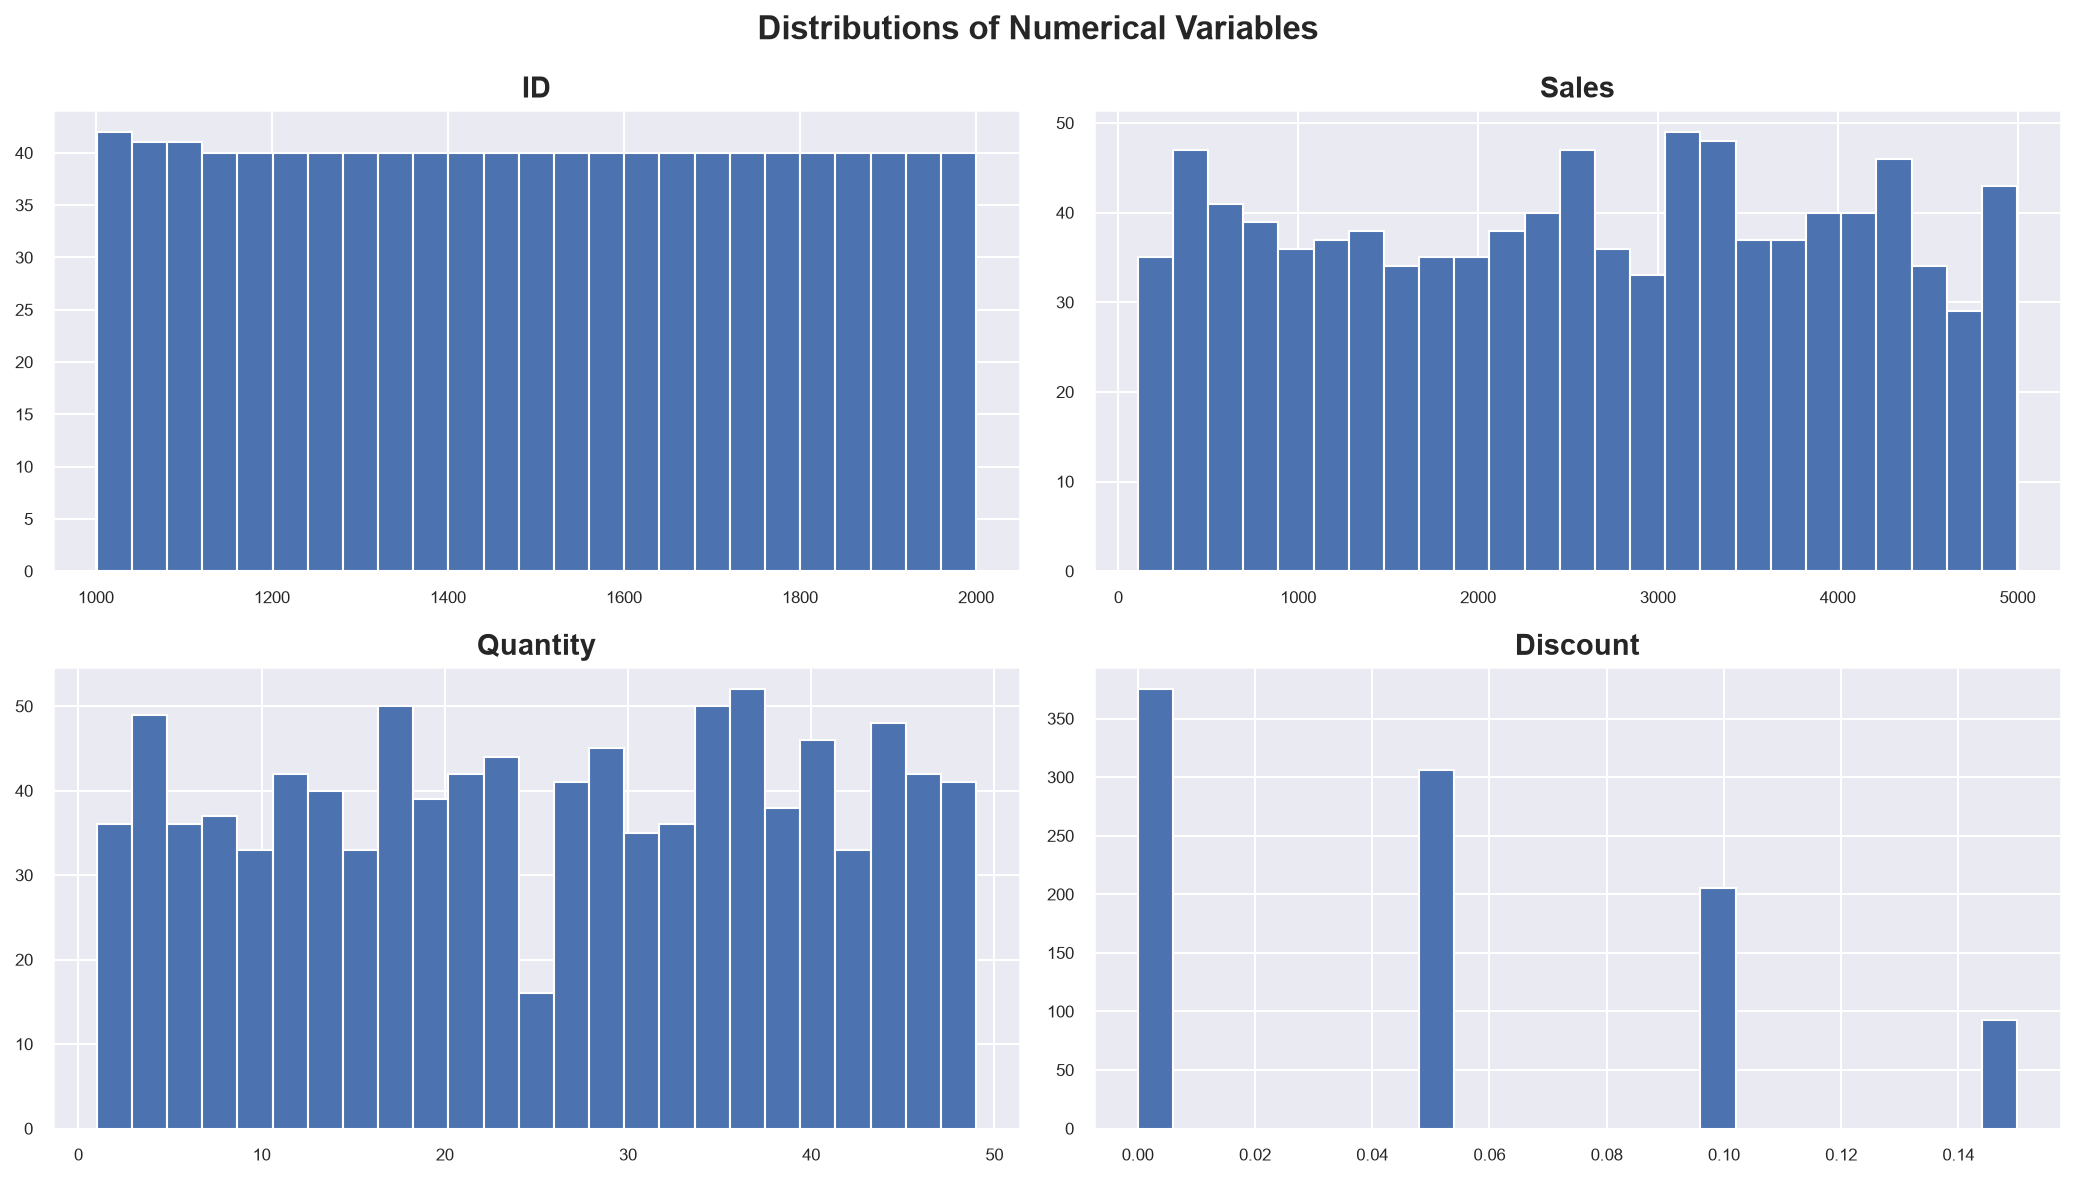

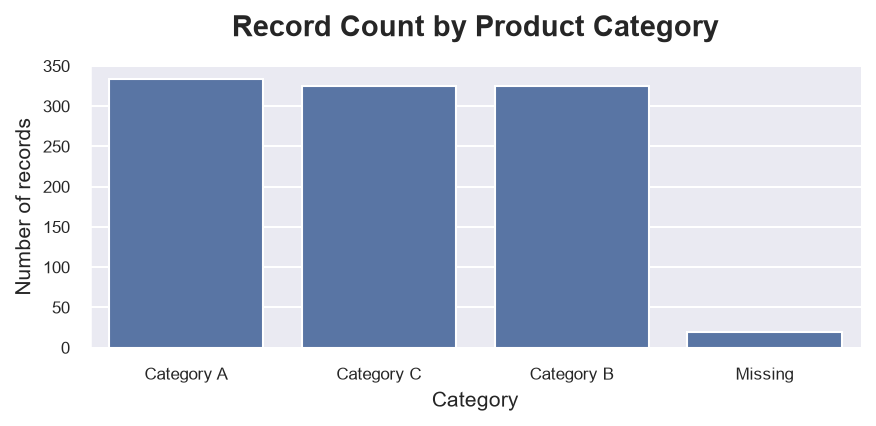

In [47]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
category_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if numeric_cols:
    df[numeric_cols].hist(figsize=(14,8), bins=25)
    plt.suptitle(
        'Distributions of Numerical Variables',
        fontsize=16, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()
    
if 'Category' in df.columns:
    plt.figure(figsize=(6,3))

    plot_data = df.copy()
    
    plot_data['Category'] = (plot_data['Category'].fillna('Missing').astype(str))
    order = plot_data['Category'].value_counts().index.tolist()
    
    sns.countplot(data=plot_data, x='Category', order=order)
    finish_plot('Record Count by Product Category', 'Category', 'Number of records')

In [48]:
print(df.isna().sum())

ID                0
Date              0
Category         20
Sales            30
Quantity          0
Discount         25
Customer_Code     0
dtype: int64


In [49]:
print((df.isnull().mean() * 100).round(2))

ID               0.00
Date             0.00
Category         1.99
Sales            2.99
Quantity         0.00
Discount         2.49
Customer_Code    0.00
dtype: float64


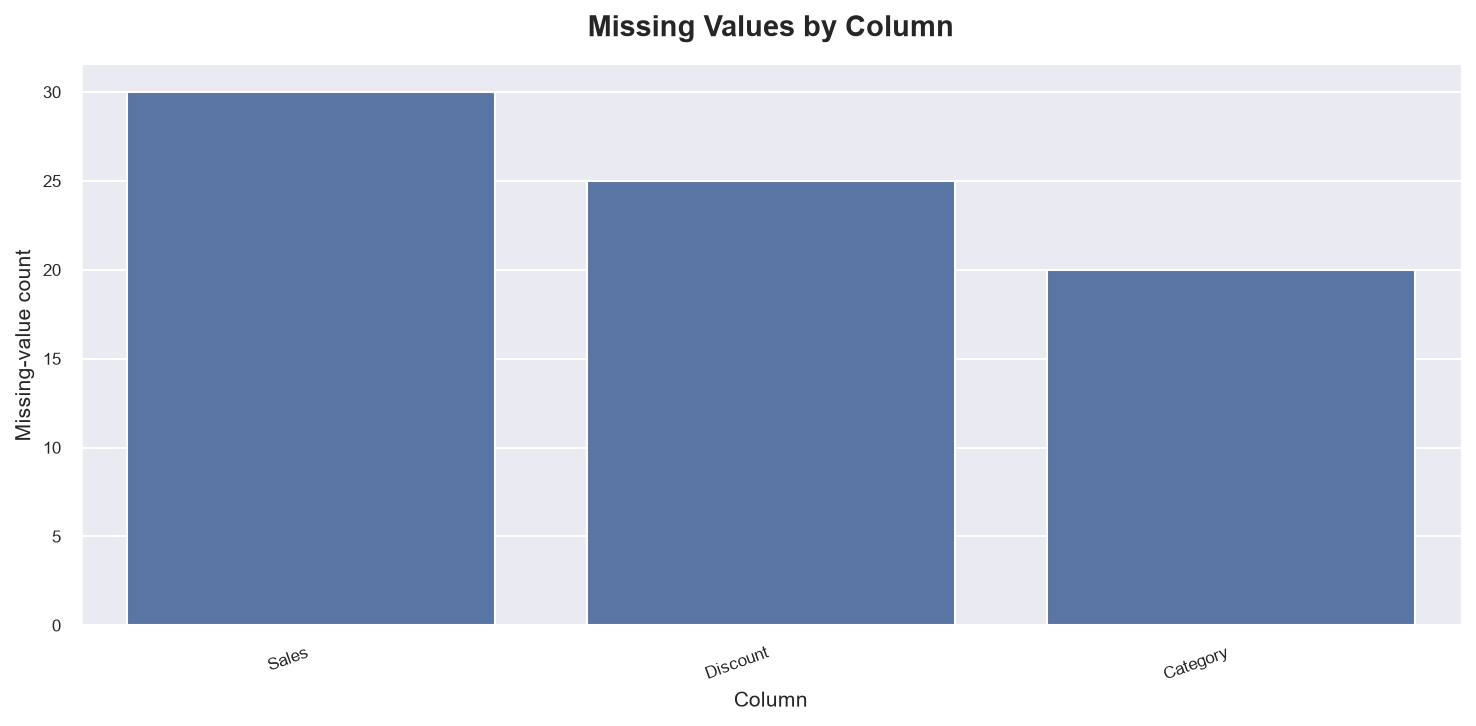

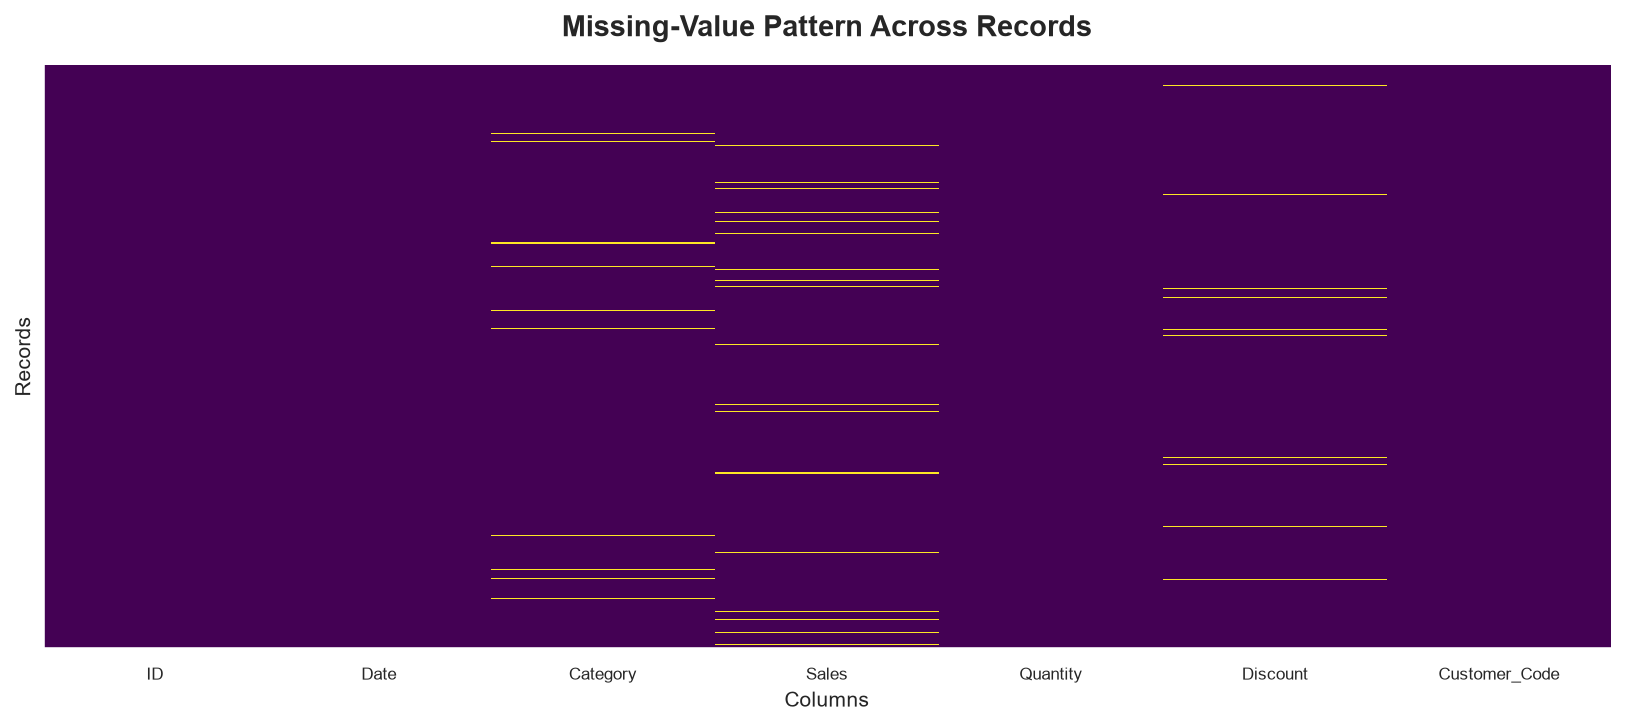

In [50]:
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]

if not missing_counts.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing_counts.index, y=missing_counts.values)
    finish_plot('Missing Values by Column', 'Column', 'Missing-value count', rotation=20)

plt.figure(figsize=(11, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap='viridis')
finish_plot('Missing-Value Pattern Across Records', 'Columns', 'Records')

In [51]:
df_clean = df.copy()
if 'Sales' in df_clean.columns:
    df_clean['Sales'] = df_clean['Sales'].fillna(df_clean['Sales'].median())
if 'Discount' in df_clean.columns:
    df_clean['Discount'] = df_clean['Discount'].fillna(0.0)
if 'Category' in df_clean.columns:
    df_clean['Category'] = df_clean['Category'].ffill().bfill()

Before-and-After Imputation Comparison

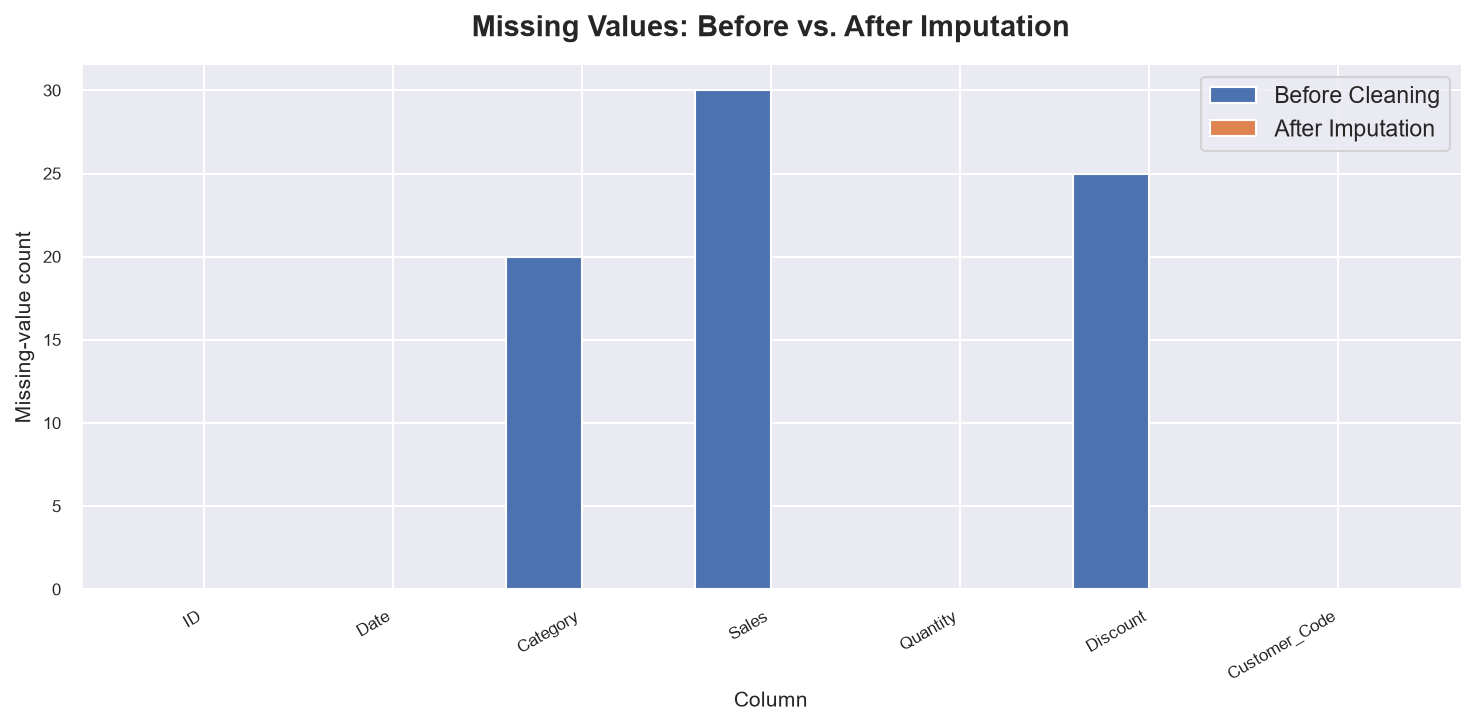

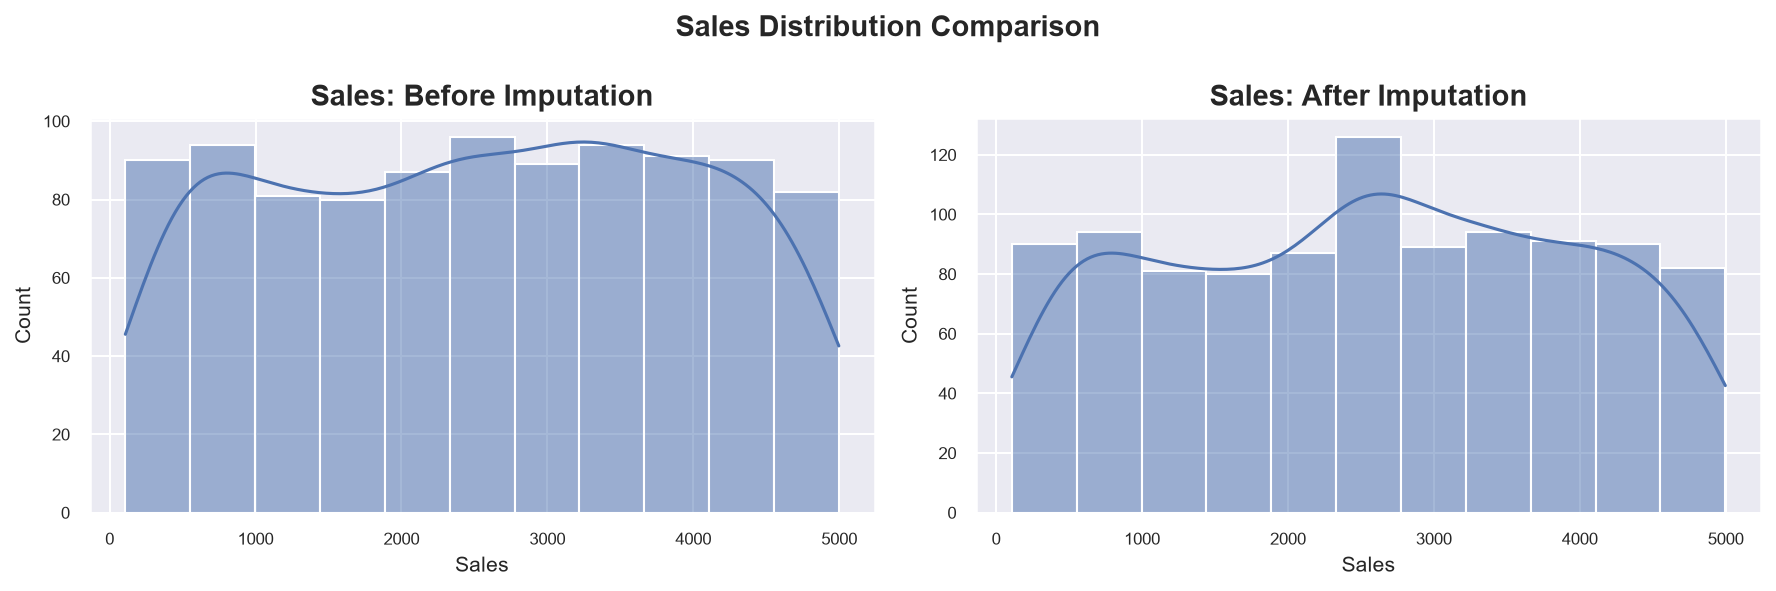

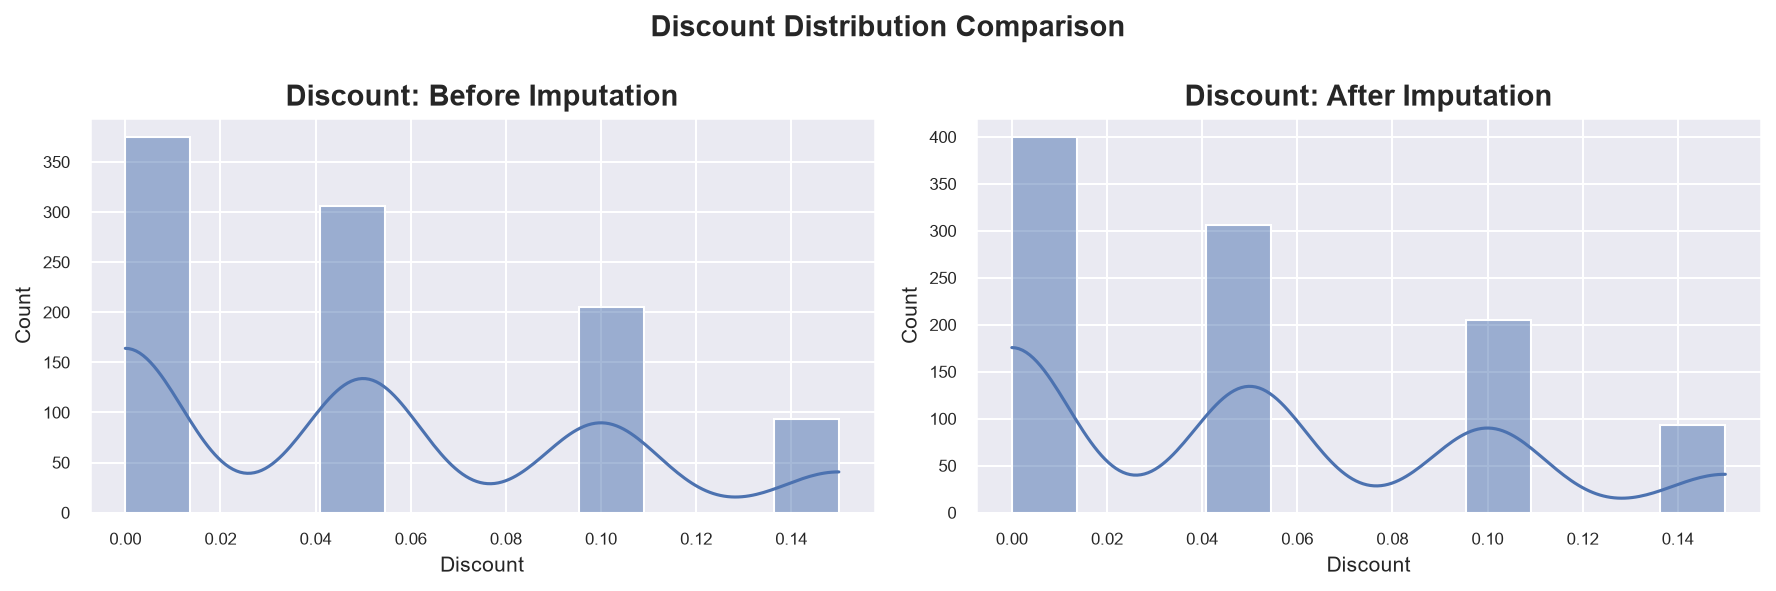

In [52]:
# Compare missingness before and after the current imputation strategy
compare_missing = pd.DataFrame(
    {"Before Cleaning": df.isna().sum(), "After Imputation": df_clean.isna().sum()}
)
compare_missing.plot(kind="bar", figsize=(10, 5), width=0.8)
finish_plot(
    "Missing Values: Before vs. After Imputation",
    "Column",
    "Missing-value count",
    rotation=30,
)

for col in ["Sales", "Discount"]:
    if col in df.columns and col in df_clean.columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
        sns.histplot(df[col].dropna(), 
                        kde=True, 
                        ax=axes[0])
        axes[0].set_title(f"{col}: Before Imputation")
        
        sns.histplot(df_clean[col].dropna(),
                        kde=True, 
                        ax=axes[1])
        axes[1].set_title(f"{col}: After Imputation")
        
        fig.suptitle(f"{col} Distribution Comparison", fontsize=14, fontweight="bold")
        plt.tight_layout()
        plt.show()


In [53]:
print("Total Duplicated row")
print(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

Total Duplicated row
4


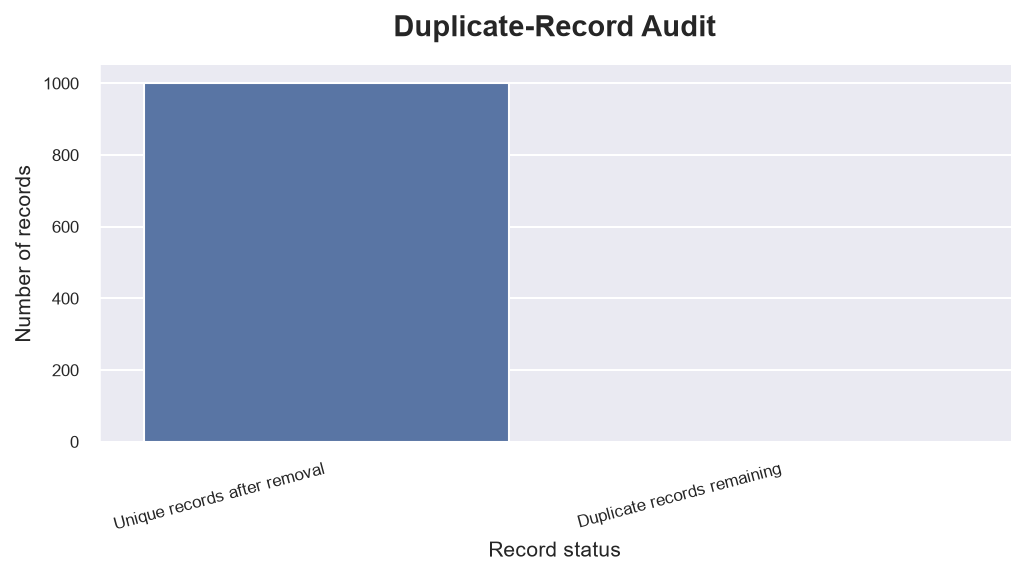

In [54]:
duplicate_count = df_clean.duplicated().sum()
unique_count = len(df_clean)

summary_duplicates = pd.Series(
    {'Unique records after removal': unique_count, 
        'Duplicate records remaining': duplicate_count
    }
)

plt.figure(figsize=(7, 4))
sns.barplot(x=summary_duplicates.index, y=summary_duplicates.values)
finish_plot('Duplicate-Record Audit', 'Record status', 'Number of records', rotation=15)


In [55]:
if 'Customer_Code' in df_clean.columns:
    df_clean['Customer_Code'] = df_clean['Customer_Code'].str.strip().str.lower().str.replace('cust-', 'C-')

In [56]:
if 'Date' in df_clean.columns:
    df_clean['Date'] = pd.to_datetime(df_clean['Date'])
    df_clean['Year'] = df_clean['Date'].dt.year
    df_clean['Month'] = df_clean['Date'].dt.month_name()
    df_clean['DayOfWeek'] = df_clean['Date'].dt.day_name()

df_clean = df_clean.rename(columns={'Sales': 'Total_Sales', 'Quantity': 'Units_Sold'})
df_clean['Units_Sold'] = df_clean['Units_Sold'].astype(int)

if 'Total_Sales' in df_clean.columns:
    df_clean['Sales_Level'] = pd.cut(df_clean['Total_Sales'], bins=[0, 1000, 3000, 10000], labels=['Low', 'Medium', 'High'])

display(df_clean.head())

,ID,Date,Category,Total_Sales,Units_Sold,Discount,Customer_Code,Year,Month,DayOfWeek,Sales_Level
0,1001,2023-04-13,Category C,2484.68,20,0.0,C-0001,2023,April,Thursday,Medium
1,1002,2023-12-15,Category C,4379.77,6,0.0,C-0002,2023,December,Friday,High
2,1003,2023-09-28,Category A,4513.44,27,0.0,C-0003,2023,September,Thursday,High
3,1004,2023-04-17,Category B,2166.43,2,0.0,C-0004,2023,April,Monday,Medium
4,1005,2023-03-13,Category B,1456.46,29,0.0,C-0005,2023,March,Monday,Medium


### Transformation & Feature-Engineering Visuals

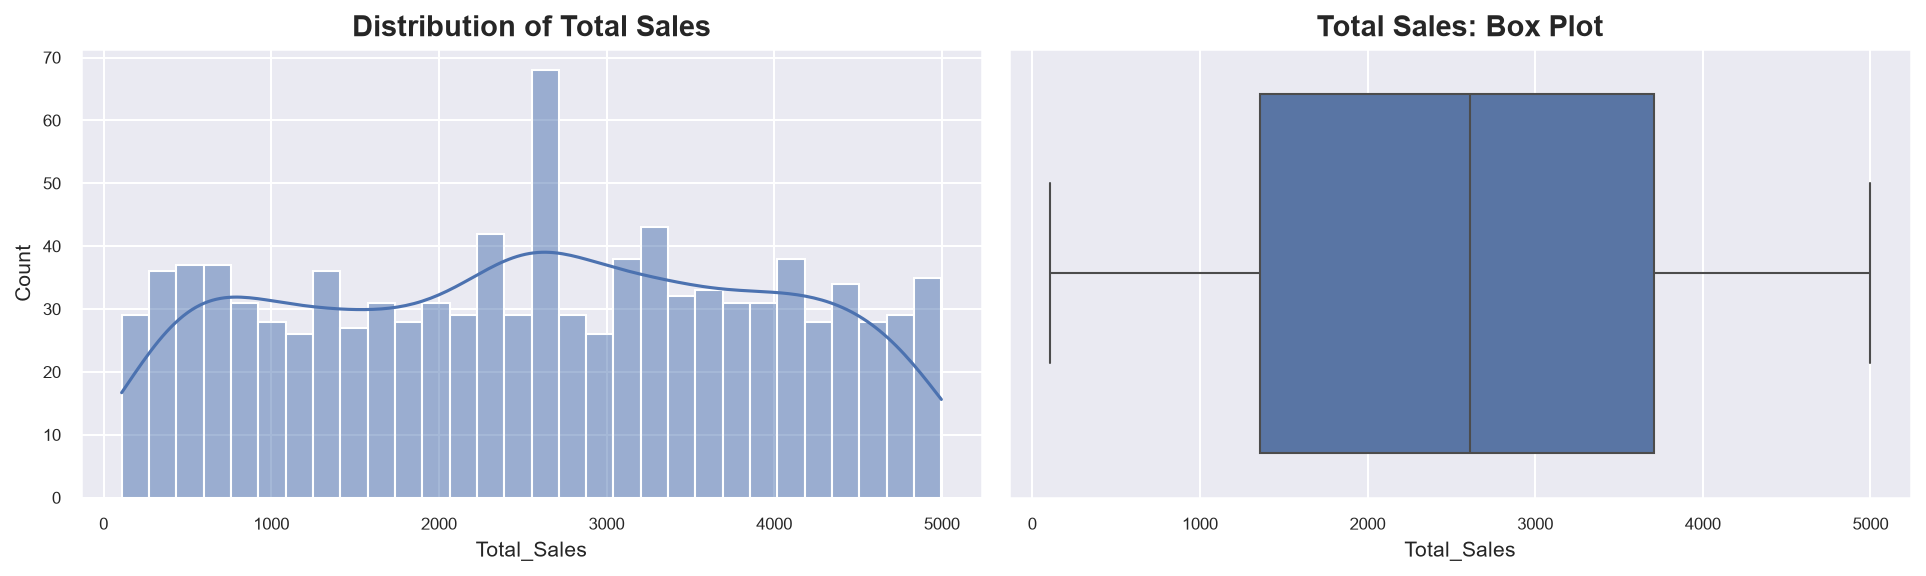

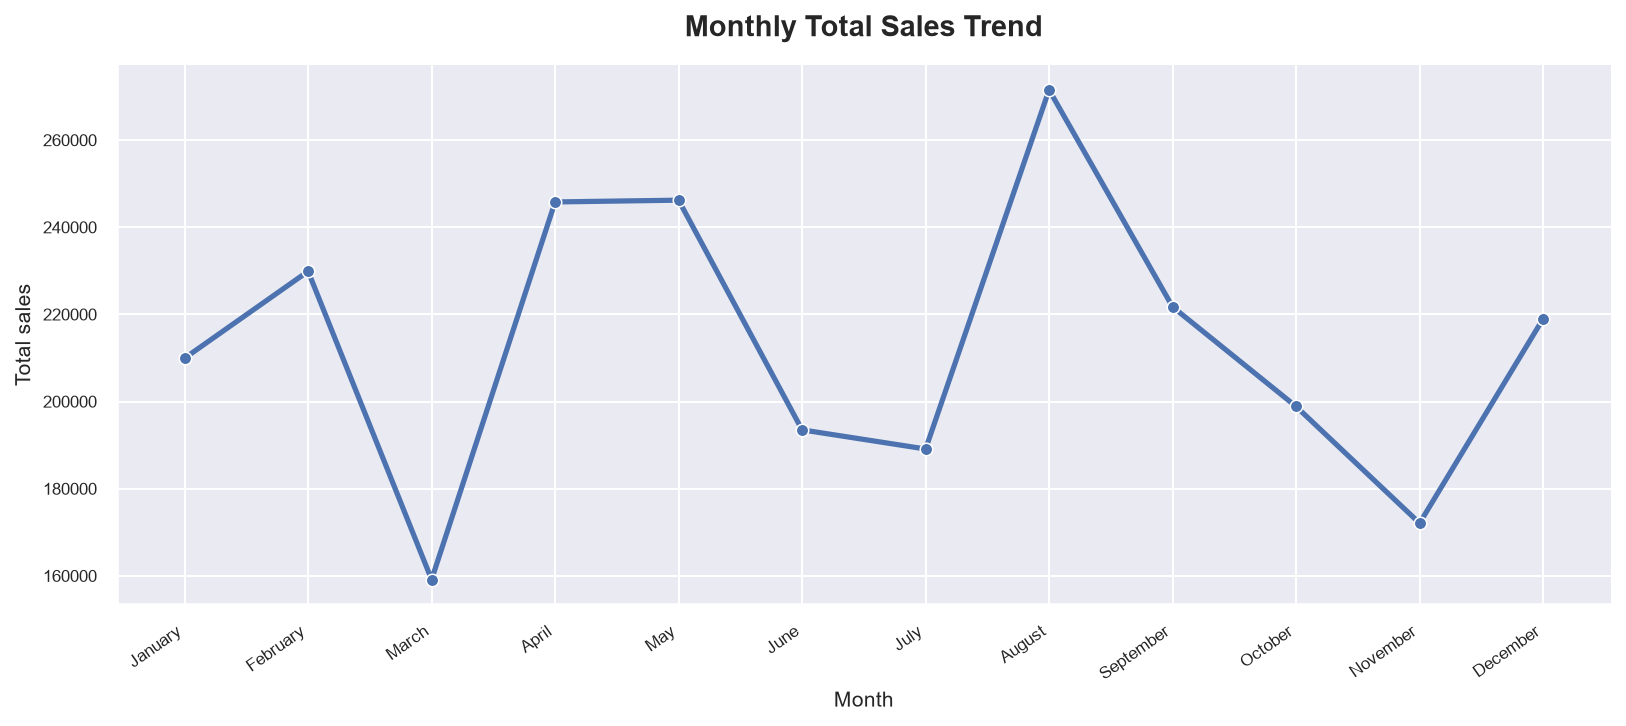

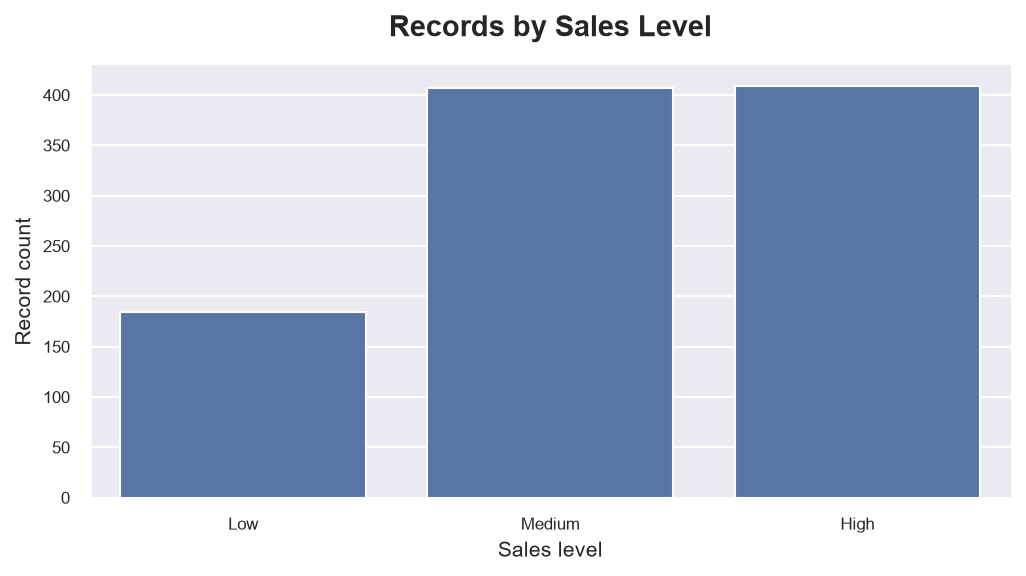

In [57]:
if "Total_Sales" in df_clean.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    sns.histplot(df_clean["Total_Sales"].dropna(), bins=30, kde=True, ax=axes[0])
    axes[0].set_title("Distribution of Total Sales")
    
    sns.boxplot(x=df_clean["Total_Sales"], ax=axes[1])
    axes[1].set_title("Total Sales: Box Plot")
    
    plt.tight_layout()
    plt.show()

if 'Month' in df_clean.columns and 'Total_Sales' in df_clean.columns:
    month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
    monthly = df_clean.groupby('Month')['Total_Sales'].sum().reindex(month_order).dropna()
    
    plt.figure(figsize=(11, 5))
    sns.lineplot(x=monthly.index, y=monthly.values, marker='o', linewidth=2.5)
    finish_plot('Monthly Total Sales Trend', 'Month', 'Total sales', rotation=35)

if 'Sales_Level' in df_clean.columns:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df_clean, x='Sales_Level', order=['Low','Medium','High'])
    finish_plot('Records by Sales Level', 'Sales level', 'Record count')

In [58]:
high_sales = df_clean.loc[(df_clean['Total_Sales'] > 2500) & (df_clean['Units_Sold'] > 10)]
subset_pos = df_clean.iloc[0:10, 0:4]

category_filter = df_clean[df_clean['Category'].isin(['Category A', 'Category B'])]
query_result = df_clean.query('Total_Sales > 2000 and Units_Sold < 30')

top_5 = df_clean.nlargest(5, 'Total_Sales')
display(top_5[['ID', 'Total_Sales', 'Units_Sold']])

,ID,Total_Sales,Units_Sold
110,1111,4997.13,42
600,1601,4991.90,44
373,1374,4983.81,15
558,1559,4982.04,7
889,1890,4977.64,31


### Filtering Results: Visual Comparison

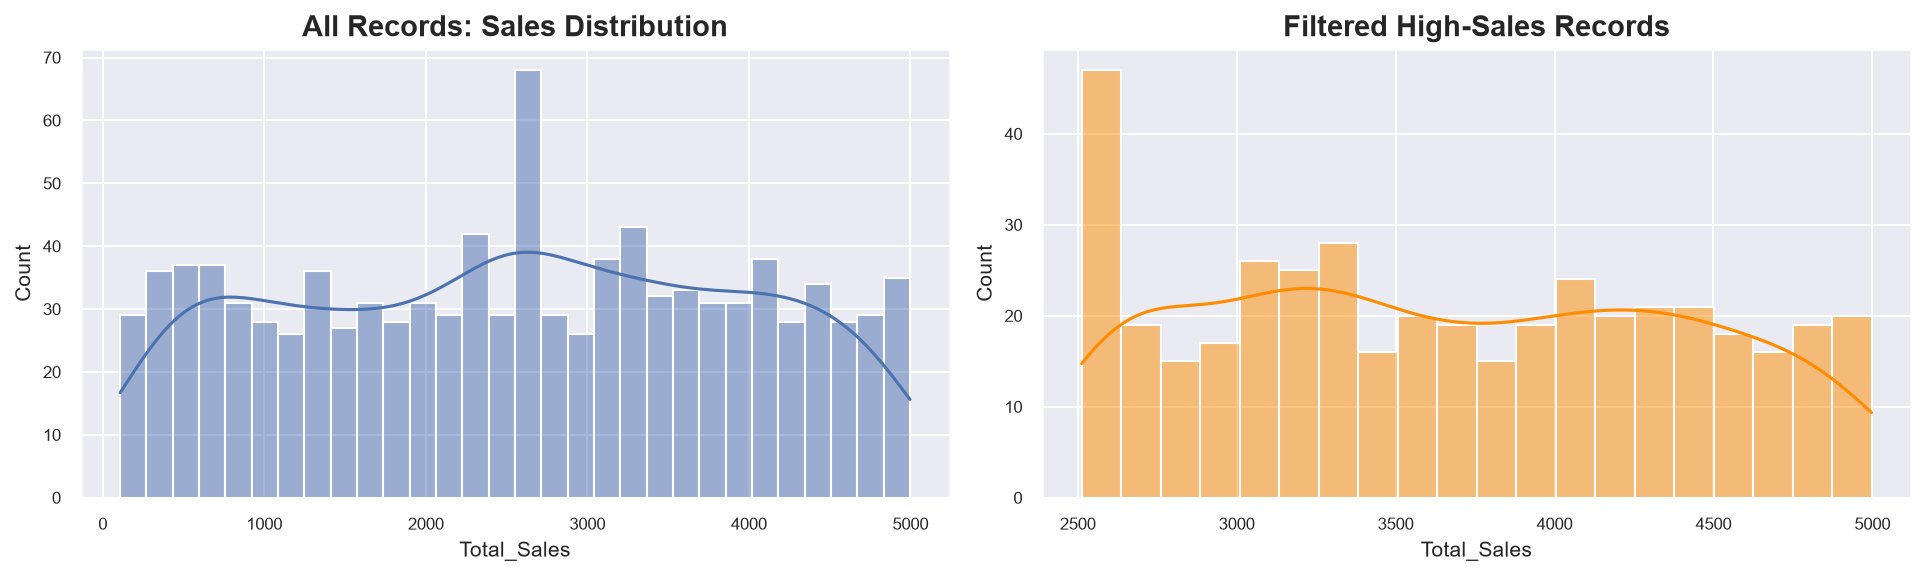

In [70]:
if "Total_Sales" in df_clean.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(
        df_clean["Total_Sales"], 
        bins=30, 
        kde=True, 
        ax=axes[0], 
        label="All records"
    )
    axes[0].set_title("All Records: Sales Distribution")
    
    if "high_sales" in globals() and not high_sales.empty:
        sns.histplot(
            high_sales["Total_Sales"], 
            bins=20, 
            kde=True, 
            ax=axes[1], 
            color="darkorange"
        )
        axes[1].set_title("Filtered High-Sales Records")
        

    plt.tight_layout()
    plt.show()

In [59]:
grp_summary = df_clean.groupby('Category').agg(
    Mean_Sales=('Total_Sales', 'mean'),
    Total_Units=('Units_Sold', 'sum'),
    Min_Sales=('Total_Sales', 'min'),
    Max_Sales=('Total_Sales', 'max'),
    Record_Count=('ID', 'count')
).reset_index()
display(grp_summary)

pivot_tb = pd.pivot_table(df_clean, values='Total_Sales', index='Category', columns='Sales_Level', aggfunc='sum', fill_value=0)
display(pivot_tb)

,Category,Mean_Sales,Total_Units,Min_Sales,Max_Sales,Record_Count
0,Category A,2574.819524,8351,128.22,4983.81,336
1,Category B,2452.646000,8532,126.98,4997.13,330
2,Category C,2641.627216,8566,107.67,4991.90,334


Sales_Level,Low,Medium,High
Category,,,
Category A,39042.20,264536.44,561560.72
Category B,36202.63,267091.77,506078.78
Category C,26569.72,304727.19,551006.58


### Top- and Bottom-Performing Records

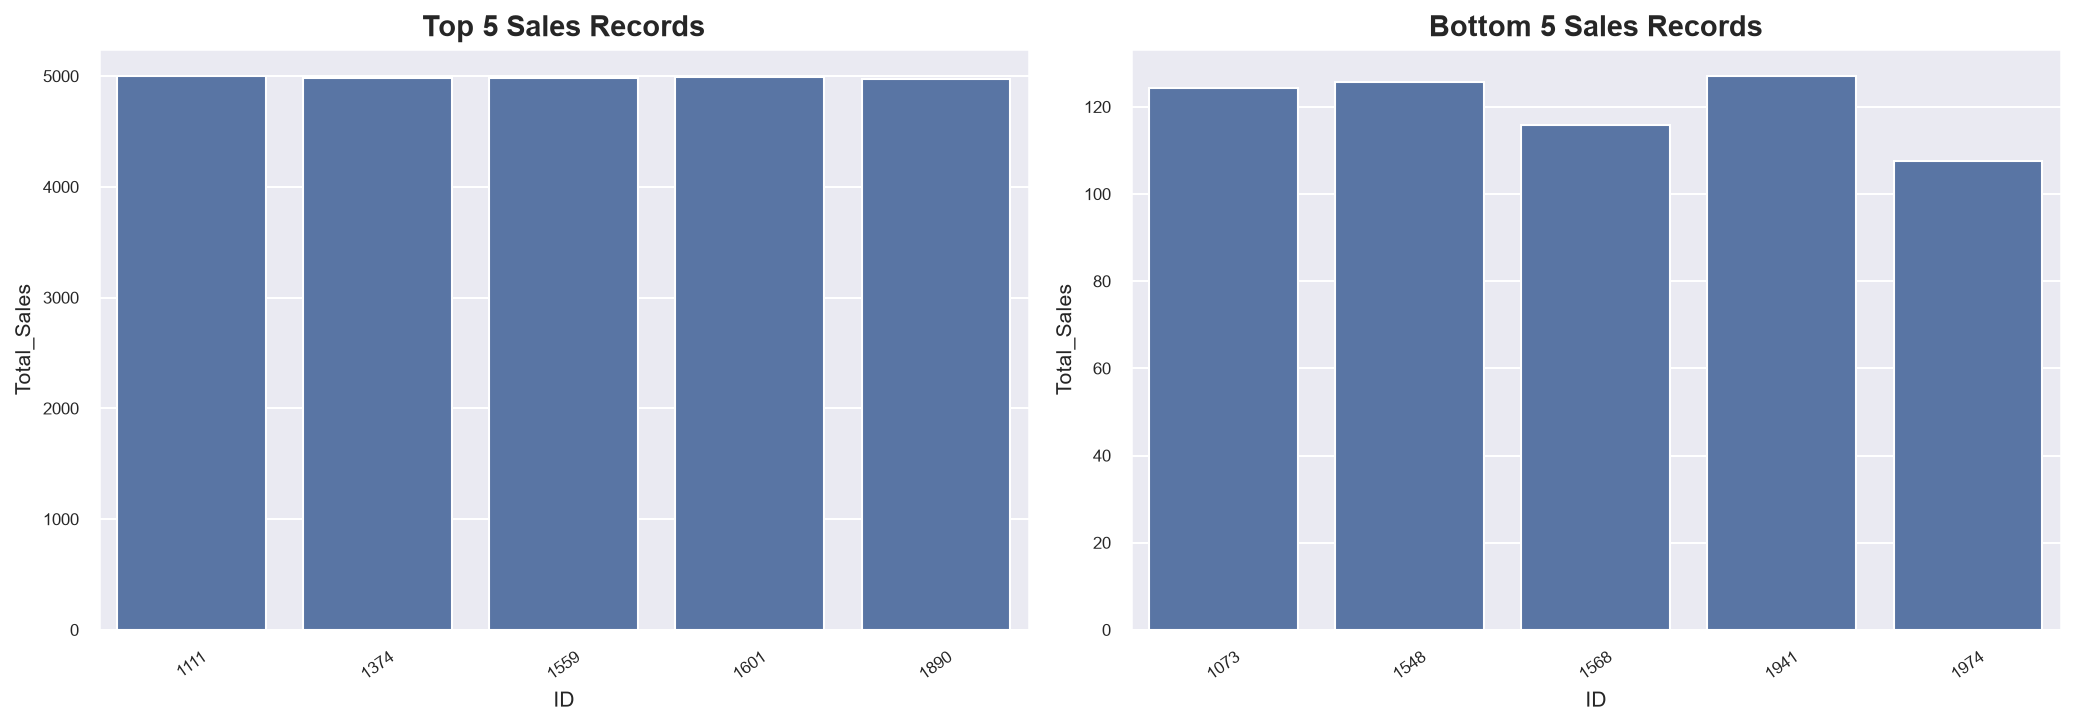

In [60]:
if 'Total_Sales' in df_clean.columns:
    bottom_5 = df_clean.nsmallest(5, 'Total_Sales')
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    if 'ID' in top_5.columns:
        sns.barplot(data=top_5, x='ID', y='Total_Sales', ax=axes[0])
        axes[0].tick_params(axis='x', rotation=35)
    axes[0].set_title('Top 5 Sales Records')
    
    if 'ID' in bottom_5.columns:
        sns.barplot(data=bottom_5, x='ID', y='Total_Sales', ax=axes[1])
        axes[1].tick_params(axis='x', rotation=35)
    axes[1].set_title('Bottom 5 Sales Records')
    
    plt.tight_layout()
    plt.show()

In [61]:
cat_info = pd.DataFrame({
    'Category': ['Category A', 'Category B', 'Category C'],
    'Manager': ['Dr. Rahaman', 'Prof. Ahmed', 'Engr. Karim']
})

df_merged = pd.merge(df_clean, cat_info, on='Category', how='left')
display(df_merged.head())

,ID,Date,Category,Total_Sales,Units_Sold,Discount,Customer_Code,Year,Month,DayOfWeek,Sales_Level,Manager
0,1001,2023-04-13,Category C,2484.68,20,0.0,C-0001,2023,April,Thursday,Medium,Engr. Karim
1,1002,2023-12-15,Category C,4379.77,6,0.0,C-0002,2023,December,Friday,High,Engr. Karim
2,1003,2023-09-28,Category A,4513.44,27,0.0,C-0003,2023,September,Thursday,High,Dr. Rahaman
3,1004,2023-04-17,Category B,2166.43,2,0.0,C-0004,2023,April,Monday,Medium,Prof. Ahmed
4,1005,2023-03-13,Category B,1456.46,29,0.0,C-0005,2023,March,Monday,Medium,Prof. Ahmed


### Category-Level Business Performance Visuals

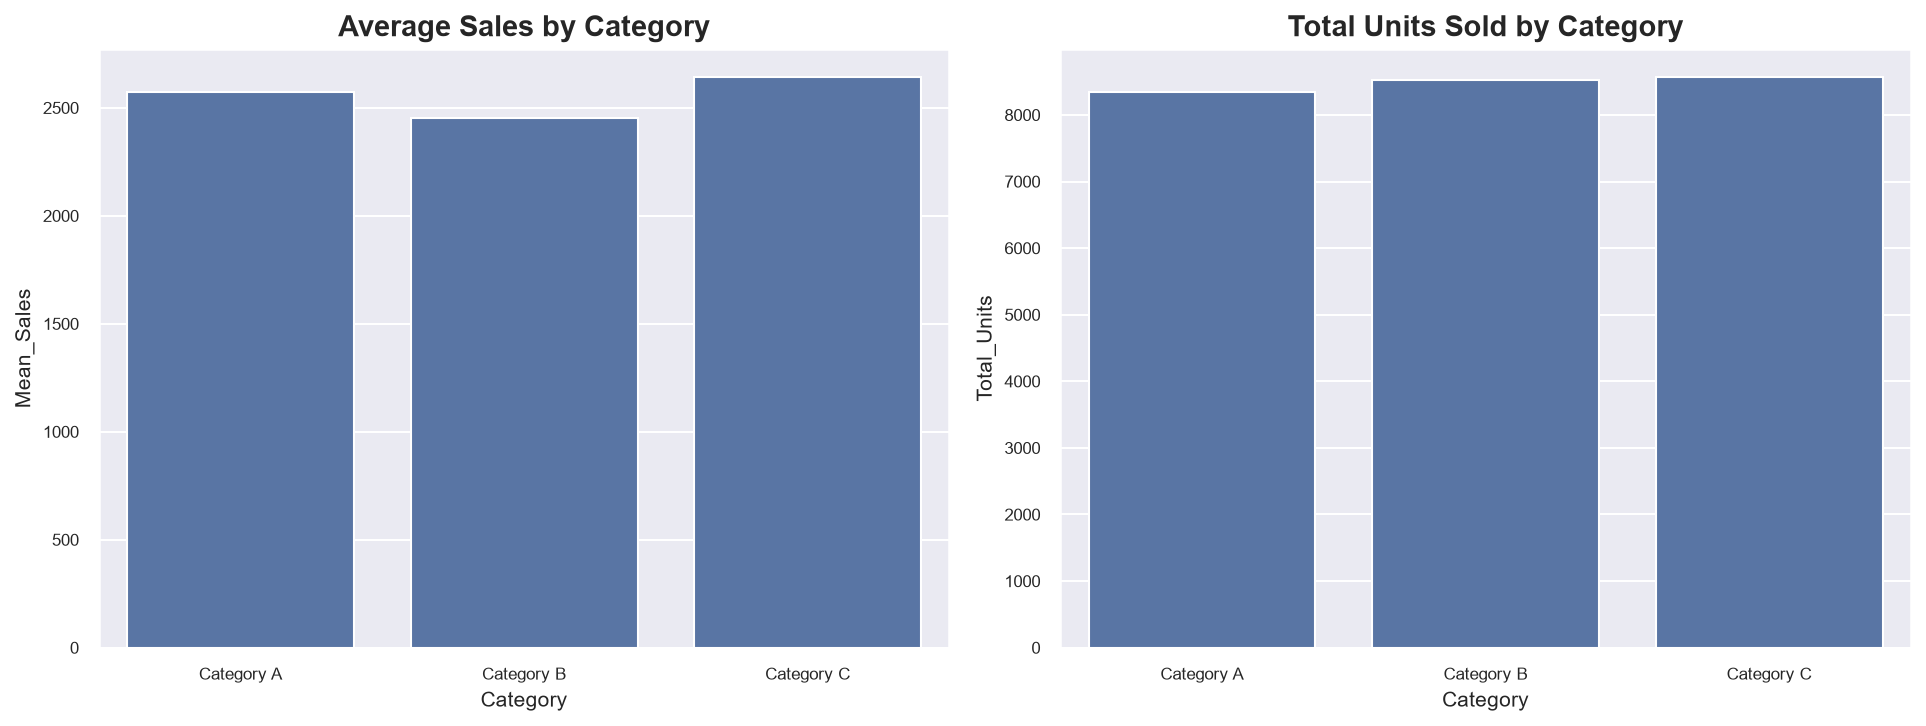

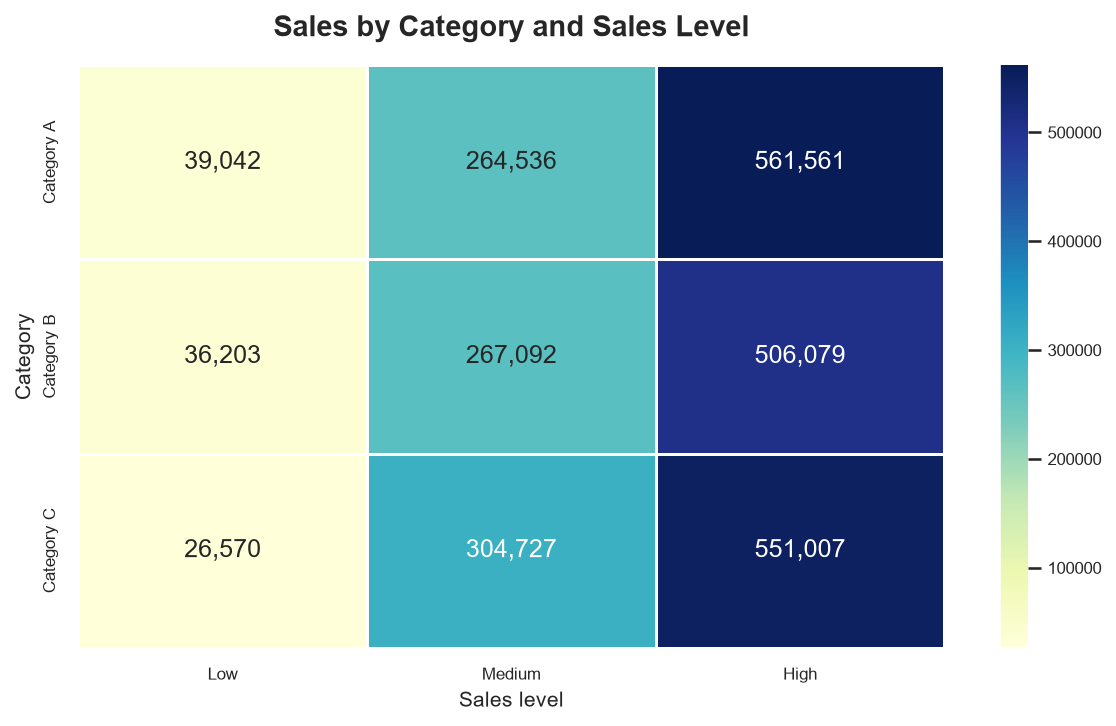

In [62]:
if not grp_summary.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    
    sns.barplot(data=grp_summary, 
                x="Category", 
                y="Mean_Sales", 
                ax=axes[0])
    axes[0].set_title('Average Sales by Category')
    
    sns.barplot(data=grp_summary, 
                x='Category', 
                y='Total_Units', 
                ax=axes[1])
    axes[1].set_title('Total Units Sold by Category')
    
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_tb, annot=True, fmt=',.0f', cmap='YlGnBu', linewidths=.5)
finish_plot('Sales by Category and Sales Level', 'Sales level', 'Category')


In [63]:
display(df_clean.describe().T)
corr_matrix = df_clean[['Total_Sales', 'Units_Sold', 'Discount']].corr()
display(corr_matrix)

# Outliers via IQR
Q1 = df_clean['Total_Sales'].quantile(0.25)
Q3 = df_clean['Total_Sales'].quantile(0.75)
IQR = Q3 - Q1
outliers = df_clean[(df_clean['Total_Sales'] < (Q1 - 1.5 * IQR)) | (df_clean['Total_Sales'] > (Q3 + 1.5 * IQR))]
print("Outliers Count:", len(outliers))

,count,mean,min,25%,50%,75%,max,std
ID,1000.0,1500.5,1001.0,1250.75,1500.5,1750.25,2000.0,288.819436
Date,1000,2023-07-01 13:22:04.800000,2023-01-01 00:00:00,2023-04-08 00:00:00,2023-07-01 12:00:00,2023-09-27 06:00:00,2023-12-31 00:00:00,NaN
Total_Sales,1000.0,2556.81603,107.67,1361.2625,2610.92,3711.2725,4997.13,1389.03032
Units_Sold,1000.0,25.449,1.0,13.0,26.0,37.0,49.0,14.126888
Discount,1000.0,0.0496,0.0,0.0,0.05,0.1,0.15,0.049419
Year,1000.0,2023.0,2023.0,2023.0,2023.0,2023.0,2023.0,0.0


,Total_Sales,Units_Sold,Discount
Total_Sales,1.000000,0.038797,-0.049479
Units_Sold,0.038797,1.000000,0.000903
Discount,-0.049479,0.000903,1.000000


Outliers Count: 0


### Merged Dataset: Category Manager View

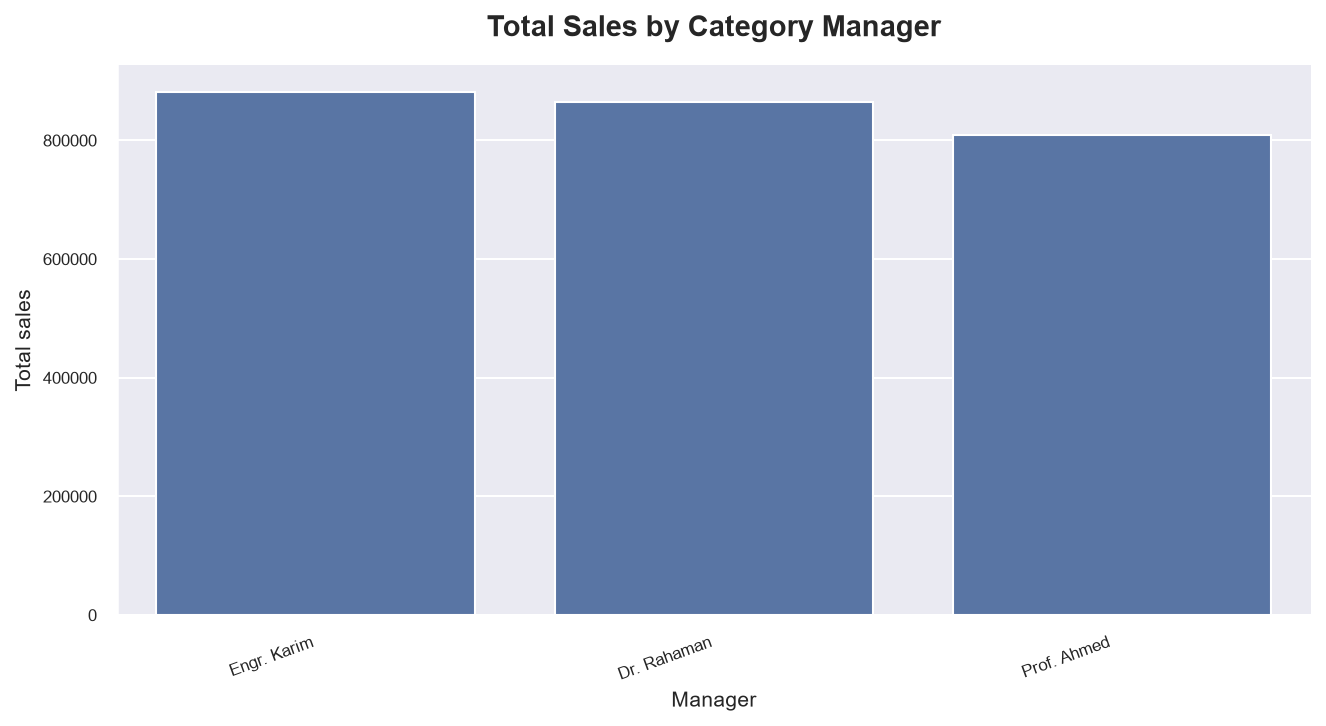

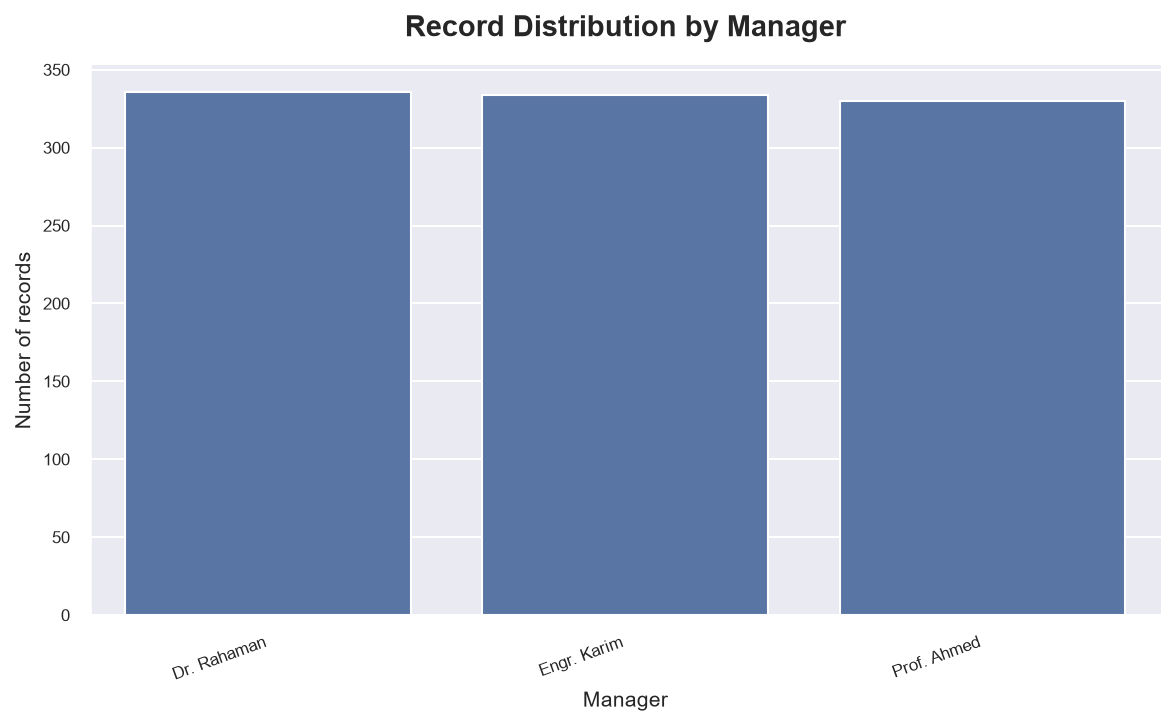

In [64]:
if 'Manager' in df_merged.columns and 'Total_Sales' in df_merged.columns:
    manager_summary = df_merged.groupby('Manager', dropna=False)['Total_Sales'].sum().sort_values(ascending=False).reset_index()
    
    plt.figure(figsize=(9, 5))
    sns.barplot(data=manager_summary, 
                x='Manager', 
                y='Total_Sales')
    finish_plot('Total Sales by Category Manager', 'Manager', 'Total sales', rotation=20)

if 'Manager' in df_merged.columns:
    manager_counts = df_merged['Manager'].fillna('Unassigned').value_counts().reset_index()
    manager_counts.columns = ['Manager', 'Records']
    
    plt.figure(figsize=(8, 5))
    sns.barplot(data=manager_counts, 
                x='Manager', 
                y='Records')
    finish_plot('Record Distribution by Manager', 'Manager', 'Number of records', rotation=20)


### Statistical Analysis, Correlation & Outlier Visualizations

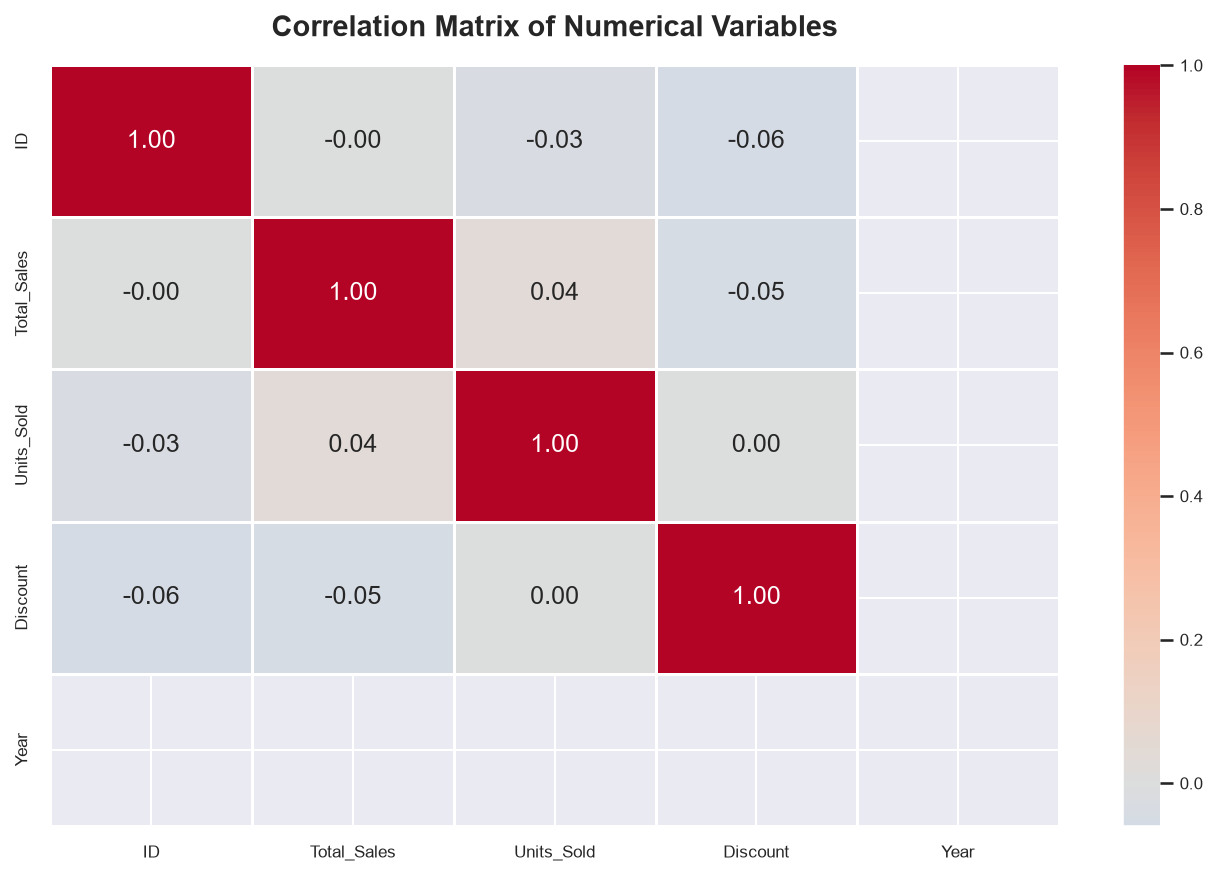

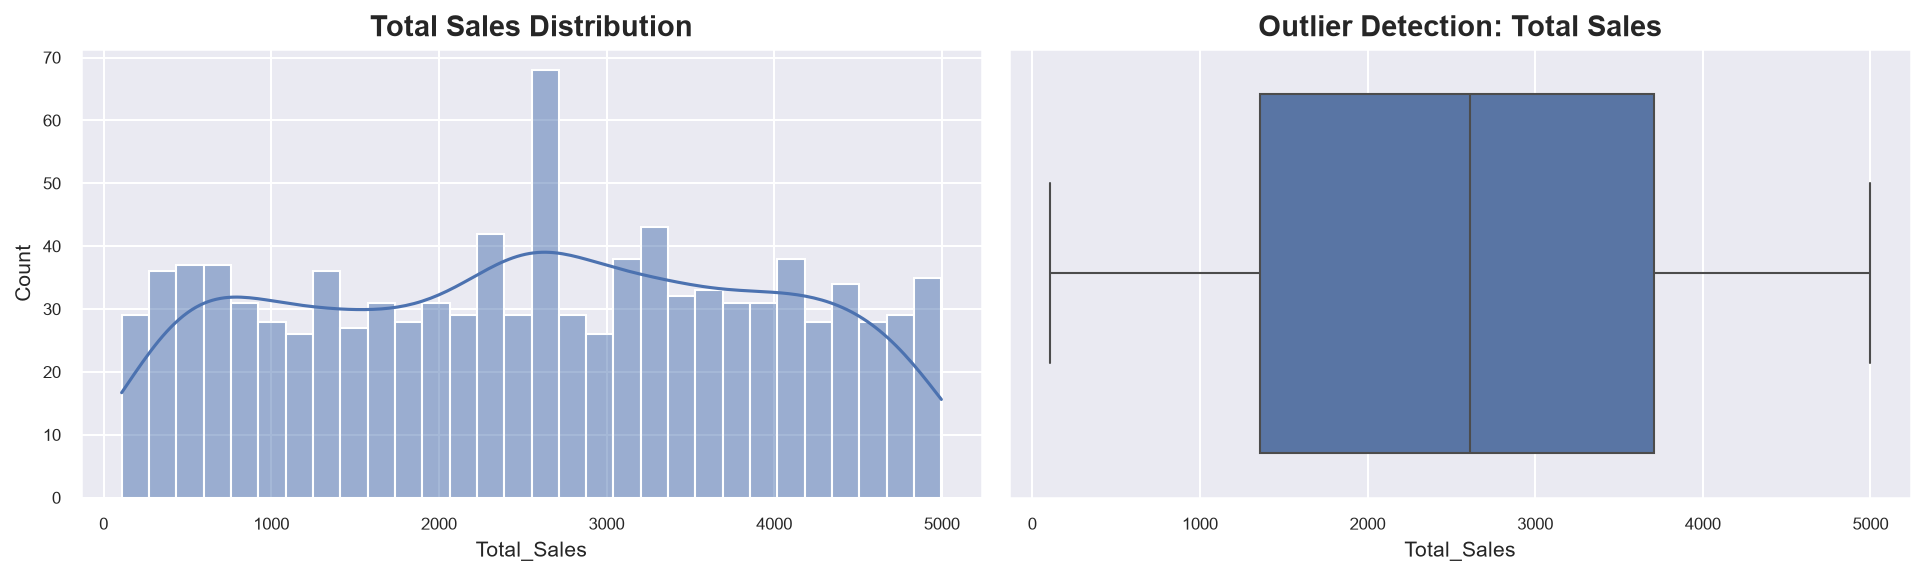

In [65]:
numeric_for_corr = df_clean.select_dtypes(include=np.number)

if numeric_for_corr.shape[1] >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(numeric_for_corr.corr(), 
                annot=True, 
                cmap='coolwarm', 
                center=0, 
                fmt='.2f', 
                linewidths=.5)
    finish_plot('Correlation Matrix of Numerical Variables')

# Distribution and outlier diagnostics
if 'Total_Sales' in df_clean.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    
    sns.histplot(df_clean['Total_Sales'], 
                    bins=30, 
                    kde=True, 
                    ax=axes[0])
    axes[0].set_title('Total Sales Distribution')
    
    sns.boxplot(x=df_clean['Total_Sales'], 
                ax=axes[1])
    axes[1].set_title('Outlier Detection: Total Sales')
    
    plt.tight_layout()
    plt.show()

    if not outliers.empty:
        plt.figure(figsize=(10, 5))
        sns.scatterplot(data=df_clean, 
                        x=df_clean.index, 
                        y='Total_Sales', 
                        hue=df_clean.index.isin(outliers.index), 
                        palette={False:'steelblue', True:'crimson'}, 
                        legend=False, alpha=.75)
        finish_plot('IQR-Based Sales Outliers', 'Record index', 'Total sales')


### Final Dataset Quality & Export Summary

,Metric,Value
0,Rows,1000
1,Columns,11
2,Duplicate rows,0
3,Total missing cells,0


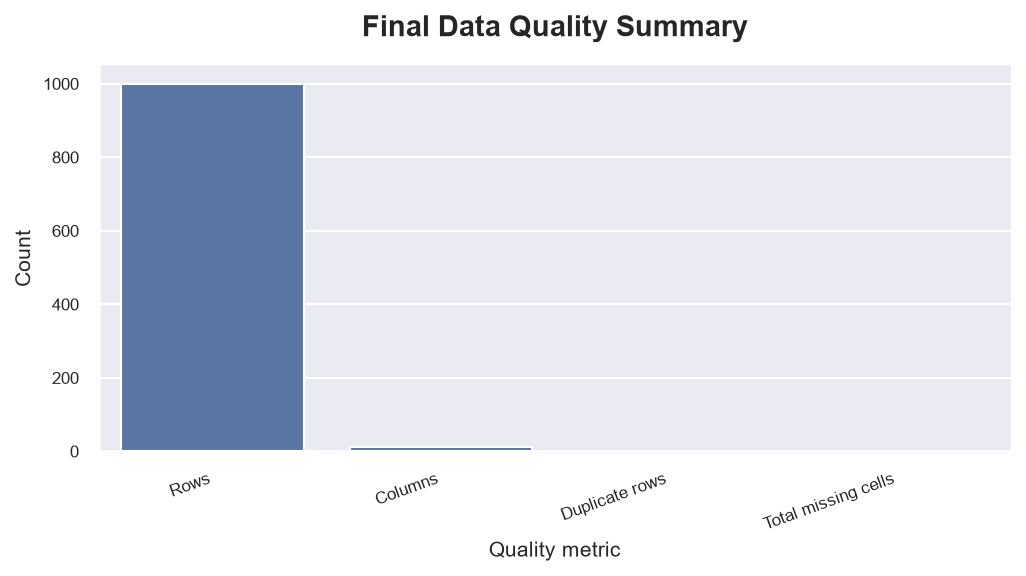

In [66]:

quality_summary = pd.DataFrame({
    'Metric': ['Rows', 'Columns', 'Duplicate rows', 'Total missing cells'],
    'Value': [len(df_clean), df_clean.shape[1], df_clean.duplicated().sum(), int(df_clean.isna().sum().sum())]
})
display(quality_summary)

plt.figure(figsize=(7, 4))
sns.barplot(data=quality_summary, 
            x='Metric', 
            y='Value')

finish_plot('Final Data Quality Summary', 'Quality metric', 'Count', rotation=20)
